# 02 · `gmsEDA` decomposition **without per-subject normalisation**

**Question.** Does decomposing each 1-min E4 EDA window with `eda_proj.gms_eda.gmsEDA` improve
baseline-vs-stress classification when **no per-subject normalisation** is used? Here every feature is computed
on the window in µS. This is the harder setting, because skin-conductance levels differ more than 10× between people.

**Setup.** Windows come from notebook 01: 60 s windows with a 10 s stride and 100 % label purity, cut with the
project's `reshape_function` (set `WINDOWING = "block"` below for block-aligned windows; caches are kept per scheme).
Evaluation is leave-one-subject-out (LOSO) over the 15 subjects.

* `raw`: the 33 signal features of `raw_features`, in µS.
* `raw+rel`: `raw` plus 14 scale-free ratios (spread / slope / derivative / peak features divided by the window
  mean). This is a control, because the decomposition features also contain a few such ratios.
* `gms`: 28 features of the `gmsEDA` output, with tonic, phasic, positive and negative driver parts, and 6 scale-free
  ratios (`eda_utils.gms_signed_features`).
* `med`: the same 28 features computed from a naive running-median decomposition. This is the control for
  "any tonic/phasic split".

**`gmsEDA` parameters explored.** `src/eda_proj/gms_eda.py` now accepts `lam_scale` (λ = lam_scale/√max(N,K);
default 3 as before):

| parameter | values |
|---|---|
| `num_of_chops` | 2, 3, 5, 10, 20, 30, 40, 60 |
| `overlap` | 0, 0.5, 0.8, 0.9, 0.95 |
| `lam_scale` | 0.3, 0.5, 1, 2, 3, 10 |
| `force_nn` | 0 (new default), 1 |

There are 112 configurations. The full grid is 5 chops × 4 overlaps × 5 λ, plus a refinement around the best region.
Decomposing the ~2,600 windows takes 10–240 s per configuration, so only the resulting feature tables are cached
(`cache/<WINDOWING>/gms_grid_features_part*.npz`).

**Avoiding selection bias.** Picking the best of 112 configurations on the same LOSO results is optimistic.
Section 4 therefore runs a **nested LOSO**: for each held-out subject, the configuration is chosen by an inner
5-fold group CV on the other 14 subjects only. "No decomposition" is also one of the candidates.

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import warnings, time, itertools
warnings.filterwarnings("ignore")
from eda_utils import *
from eda_proj.gms_eda import gmsEDA
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import HistGradientBoostingClassifier
pd.set_option("display.width", 220); pd.set_option("display.max_columns", 30)

WINDOWING = "reshape"   # "reshape" (default: eda_proj.features.reshape_function) or "block"; see notebook 01
LABELS = (1, 2)         # WESAD conditions in the task: 1 baseline, 2 stress, 3 amusement, 4 meditation
MERGE = {}              # optional label merging, e.g. {3: 1} = amusement counted with baseline (stress vs non-stress)
STRIDE = 10
# per-window caches (decompositions, features) live in cache/<WINDOWING>/label<k>/ and are combined for LABELS;
# results that depend on the task (screening, nested selection) live in RES:
RES = results_dir(WINDOWING, LABELS, MERGE)
W, meta = load_windows(WINDOWING, LABELS, STRIDE)
y, groups = task_labels(meta, MERGE), meta.subject.values
print(W.shape)

(2575, 240)


## 1. Baseline features (µS, no normalisation) and the running-median control

In [2]:
R = own_features(WINDOWING, LABELS, "raw")        # cached per label: label<k>/rawfeat_abs.csv
RAW = R[[c for c in R if not c.startswith("rel_")]]
RAWREL = R
MED = own_features(WINDOWING, LABELS, "med")      # label<k>/medfeat_abs.csv
print(RAW.shape, RAWREL.shape, MED.shape)

(2575, 33) (2575, 47) (2575, 28)


## 2. Grid over `num_of_chops` × `overlap` × `lam_scale`
Screening with two classifiers: logistic regression and gradient boosting.

In [3]:
# sanity check: the new lam_scale argument with its default reproduces the previous gmsEDA
X_def, _ = gmsEDA(W[500].reshape(-1, 1), FS, 5, 0.8)
X_l3, _ = gmsEDA(W[500].reshape(-1, 1), FS, 5, 0.8, lam_scale=3)
print("lam_scale=3 equals default:", np.allclose(X_def, X_l3))

GRID = gms_grid()
print(len(GRID), "configurations")
# (one configuration:  own_features(WINDOWING, LABELS, "c20_o0.9_l1_nn0"); a missing one is computed (10-240 s for
#  ~2,600 windows) and cached per label as gmsfeat_<tag>.csv, then packed into gms_grid_features_part*.npz)
GF = {t: own_features(WINDOWING, LABELS, t) for t in GRID.tag}     # missing ones are computed per label
import glob
for l in LABELS:                                    # pack newly computed configurations (gmsfeat_*.csv) per label
    if glob.glob(str(label_dir(WINDOWING, l) / "gmsfeat_*.csv")):
        pack_grid_features(label_dir(WINDOWING, l))

lam_scale=3 equals default: True
112 configurations


In [4]:
SCREEN_MODELS = {
    "LogReg": lambda: make_pipeline(StandardScaler(), LogisticRegression(max_iter=3000)),
    "HistGB": lambda: HistGradientBoostingClassifier(max_iter=300, learning_rate=0.03, max_depth=3, random_state=0),
}
f_scr = RES / "gms_grid_screen.csv"
scr = pd.read_csv(f_scr) if f_scr.exists() else pd.DataFrame(columns=["tag", "features", "model", "acc", "f1"])
todo = [t for t in GF if t not in set(scr.tag)]
t0 = time.time()
rows = []
for t in ["none"] + todo if "none" not in set(scr.tag) else todo:
    for fs, X in ([("raw", RAW)] if t == "none" else [("gms", GF[t]), ("raw+gms", pd.concat([RAW, GF[t]], axis=1))]):
        for m, fn in SCREEN_MODELS.items():
            s, _ = loso_eval(fn, X.values, y, groups)
            rows.append(dict(tag=t, features=fs, model=m, acc=s["acc"], f1=s["f1"]))
if rows:
    scr = pd.concat([scr, pd.DataFrame(rows)], ignore_index=True); scr.to_csv(f_scr, index=False)
scr = scr.astype({"acc": float, "f1": float})
print(f"{time.time() - t0:.0f}s")
base_acc = scr[scr.tag == "none"].set_index("model").acc
print("raw (no decomposition):", base_acc.round(3).to_dict(), " mean", round(base_acc.mean(), 3))

S = scr[scr.tag != "none"].pivot_table(index="tag", columns=["features", "model"], values="acc")
S.columns = [f"{a} | {b}" for a, b in S.columns]
S["mean raw+gms"] = S[["raw+gms | LogReg", "raw+gms | HistGB"]].mean(axis=1)
S["mean gms"] = S[["gms | LogReg", "gms | HistGB"]].mean(axis=1)
S = GRID.set_index("tag").join(S)
S.sort_values("mean raw+gms", ascending=False).head(15).round(3)

0s
raw (no decomposition): {'LogReg': 0.833, 'HistGB': 0.843}  mean 0.838


,num_of_chops,overlap,lam_scale,force_nn,gms | HistGB,gms | LogReg,raw+gms | HistGB,raw+gms | LogReg,mean raw+gms,mean gms
tag,,,,,,,,,,
c40_o0.8_l1_nn0,40,0.80,1.0,0,0.855,0.872,0.859,0.868,0.863,0.863
c20_o0.9_l1_nn0,20,0.90,1.0,0,0.856,0.864,0.859,0.866,0.863,0.860
c10_o0.8_l1_nn0,10,0.80,1.0,0,0.845,0.853,0.855,0.869,0.862,0.849
c20_o0.95_l1_nn0,20,0.95,1.0,0,0.871,0.846,0.870,0.854,0.862,0.859
c30_o0.8_l1_nn0,30,0.80,1.0,0,0.853,0.867,0.853,0.868,0.860,0.860
c20_o0.8_l1_nn0,20,0.80,1.0,0,0.843,0.856,0.849,0.871,0.860,0.849
c40_o0.9_l1_nn0,40,0.90,1.0,0,0.862,0.844,0.865,0.854,0.860,0.853
c30_o0.9_l1_nn0,30,0.90,1.0,0,0.853,0.845,0.864,0.853,0.858,0.849
c20_o0.5_l1_nn0,20,0.50,1.0,0,0.833,0.849,0.853,0.861,0.857,0.841


### How accuracy depends on the three parameters (full 5 × 4 × 5 grid, `force_nn=0`)
Each cell is the mean LOSO accuracy of LogReg and HistGB for `raw + gms`. The colour scale is centred on the
no-decomposition baseline, so red means better than `raw` alone and blue means worse.

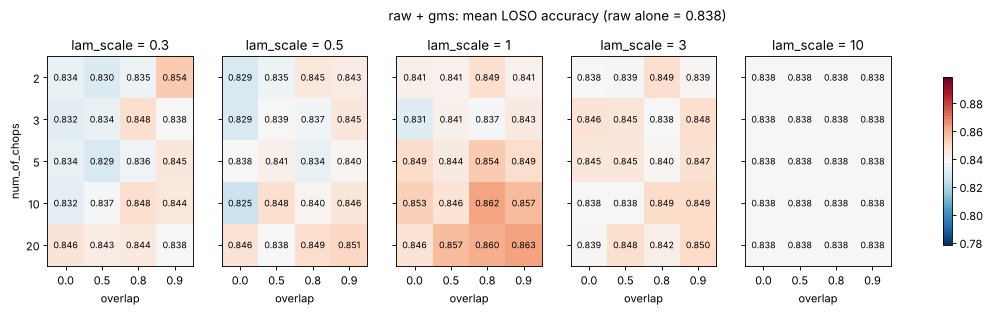

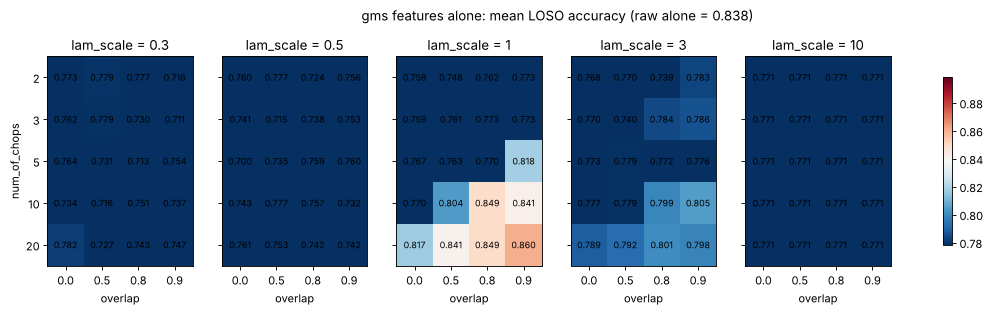

In [5]:
full = S[(S.num_of_chops.isin([2, 3, 5, 10, 20])) & (S.overlap.isin([0, .5, .8, .9])) & (S.force_nn == 0)]
lams = [0.3, 0.5, 1, 3, 10]
b = base_acc.mean()
for col, title in [("mean raw+gms", "raw + gms"), ("mean gms", "gms features alone")]:
    fig, axes = plt.subplots(1, len(lams), figsize=(17, 3.4), sharey=True)
    for ax, lam in zip(axes, lams):
        M = full[full.lam_scale == lam].pivot(index="num_of_chops", columns="overlap", values=col)
        im = ax.imshow(M.values, cmap="RdBu_r", vmin=b - 0.06, vmax=b + 0.06, aspect="auto")
        for (i, j), v in np.ndenumerate(M.values):
            ax.text(j, i, f"{v:.3f}", ha="center", va="center", fontsize=8)
        ax.set_xticks(range(M.shape[1])); ax.set_xticklabels(M.columns)
        ax.set_yticks(range(M.shape[0])); ax.set_yticklabels(M.index)
        ax.set_title(f"lam_scale = {lam}"); ax.set_xlabel("overlap")
    axes[0].set_ylabel("num_of_chops")
    fig.suptitle(f"{title}: mean LOSO accuracy (raw alone = {b:.3f})", y=1.06); fig.colorbar(im, ax=axes, shrink=.8)
    plt.show()

Clear pattern:
* **`lam_scale ≈ 1`** is best for every chop/overlap setting. The old default 3 and larger values make the driver
  too sparse, while 0.3–0.5 make it too dense.
* **More chops** (shorter segments: 20 chops → 12 samples = 3 s) and **more overlap** (0.8–0.9) help.
  The gain levels off around 10–40 chops with 0.8–0.95 overlap (see the refinement table above).
* `force_nn=1` (clipping the driver to ≥ 0) is slightly worse than keeping the signed driver.

## 3. Best region — all four classifiers, paired per-subject tests
We pick **`num_of_chops=20, overlap=0.9, lam_scale=1`**, a point in the middle of the plateau. It is compared with
`raw`, `raw+rel` and the median control. Note that this choice was made on the same LOSO results; the unbiased estimate is in section 4.

In [6]:
BEST = "c20_o0.9_l1_nn0"
DEFAULT = "c5_o0.8_l3_nn0"
SETS = {
    "raw": RAW,
    "raw+rel": RAWREL,
    "raw+med": pd.concat([RAW, MED], axis=1),
    f"gms [{DEFAULT}] (old defaults)": GF[DEFAULT],
    f"raw+gms [{DEFAULT}]": pd.concat([RAW, GF[DEFAULT]], axis=1),
    f"gms [{BEST}]": GF[BEST],
    f"raw+gms [{BEST}]": pd.concat([RAW, GF[BEST]], axis=1),
    f"raw+rel+gms [{BEST}]": pd.concat([RAWREL, GF[BEST]], axis=1),
}
t0 = time.time()
res, ptab = compare_feature_sets(SETS, y, groups)
print(f"{time.time() - t0:.0f}s")
acc = res.pivot(index="features", columns="model", values="acc").loc[list(SETS)]
acc["mean"] = acc.mean(axis=1)
acc.round(3)

262s


model,HistGB,LogReg,RandomForest,SVM-RBF,mean
features,,,,,
raw,0.843,0.833,0.829,0.855,0.840
raw+rel,0.828,0.836,0.825,0.850,0.835
raw+med,0.846,0.828,0.834,0.866,0.844
gms [c5_o0.8_l3_nn0] (old defaults),0.784,0.761,0.790,0.796,0.783
raw+gms [c5_o0.8_l3_nn0],0.836,0.843,0.811,0.854,0.836
gms [c20_o0.9_l1_nn0],0.856,0.864,0.856,0.883,0.865
raw+gms [c20_o0.9_l1_nn0],0.859,0.866,0.855,0.882,0.866
raw+rel+gms [c20_o0.9_l1_nn0],0.853,0.862,0.856,0.883,0.863


In [7]:
f1 = res.pivot(index="features", columns="model", values="f1").loc[list(SETS)]
f1["mean"] = f1.mean(axis=1)
f1.round(3)

model,HistGB,LogReg,RandomForest,SVM-RBF,mean
features,,,,,
raw,0.825,0.808,0.809,0.833,0.819
raw+rel,0.810,0.812,0.807,0.828,0.814
raw+med,0.829,0.802,0.818,0.847,0.824
gms [c5_o0.8_l3_nn0] (old defaults),0.760,0.713,0.767,0.763,0.751
raw+gms [c5_o0.8_l3_nn0],0.816,0.821,0.791,0.834,0.815
gms [c20_o0.9_l1_nn0],0.841,0.845,0.841,0.867,0.848
raw+gms [c20_o0.9_l1_nn0],0.844,0.848,0.839,0.866,0.849
raw+rel+gms [c20_o0.9_l1_nn0],0.838,0.844,0.840,0.867,0.847


Paired per-subject comparison against `raw`. Each cell gives Δ mean subject accuracy (subjects improved / worse,
Wilcoxon p).

In [8]:
ptab.assign(cell=lambda d: d.apply(lambda r: f"{r.delta:+.3f} ({r.wins}/{r.losses}, p={r.p:.3f})", axis=1)) \
    .pivot(index="features", columns="model", values="cell").loc[list(SETS)[1:]]

model,HistGB,LogReg,RandomForest,SVM-RBF
features,,,,
raw+rel,"-0.015 (6/5, p=0.859)","+0.003 (5/6, p=0.790)","-0.003 (7/6, p=0.650)","-0.005 (4/9, p=0.600)"
raw+med,"+0.003 (6/5, p=0.657)","-0.005 (6/7, p=0.727)","+0.006 (7/4, p=0.657)","+0.011 (10/3, p=0.033)"
gms [c5_o0.8_l3_nn0] (old defaults),"-0.059 (3/11, p=0.016)","-0.072 (1/13, p=0.001)","-0.038 (4/10, p=0.056)","-0.059 (3/11, p=0.013)"
raw+gms [c5_o0.8_l3_nn0],"-0.008 (3/8, p=0.155)","+0.011 (9/5, p=0.379)","-0.017 (4/10, p=0.272)","-0.000 (5/8, p=0.753)"
gms [c20_o0.9_l1_nn0],"+0.014 (11/3, p=0.221)","+0.031 (8/4, p=0.099)","+0.029 (11/3, p=0.109)","+0.029 (10/3, p=0.075)"
raw+gms [c20_o0.9_l1_nn0],"+0.017 (11/3, p=0.198)","+0.033 (11/2, p=0.055)","+0.027 (11/3, p=0.056)","+0.027 (11/3, p=0.006)"
raw+rel+gms [c20_o0.9_l1_nn0],"+0.011 (11/3, p=0.158)","+0.029 (10/2, p=0.099)","+0.028 (11/3, p=0.074)","+0.028 (10/3, p=0.013)"


Also against the stronger control `raw+rel`: does `gmsEDA` add something beyond scale-free ratios of the raw signal?

In [9]:
_, p2 = compare_feature_sets({"raw+rel": RAWREL, f"raw+rel+gms [{BEST}]": SETS[f"raw+rel+gms [{BEST}]"]},
                             y, groups, baseline="raw+rel")
p2.round(3)

,features,model,delta,wins,losses,p
0,raw+rel+gms [c20_o0.9_l1_nn0],LogReg,0.026,12,2,0.041
1,raw+rel+gms [c20_o0.9_l1_nn0],SVM-RBF,0.033,12,1,0.002
2,raw+rel+gms [c20_o0.9_l1_nn0],RandomForest,0.031,11,3,0.011
3,raw+rel+gms [c20_o0.9_l1_nn0],HistGB,0.026,11,3,0.084


## 4. Unbiased estimate: nested LOSO with the configuration chosen inside each fold
Candidates are all 112 `raw+gms` configurations **plus `raw` alone**. Selection uses logistic regression with
inner 5-fold group CV on the 14 training subjects. The chosen feature set is then refit with LogReg and with HistGB
and tested on the held-out subject.

In [10]:
CANDS = {"raw (no decomposition)": RAW}
CANDS.update({f"raw+gms [{t}]": pd.concat([RAW, GF[t]], axis=1) for t in GF})
FINAL = {"LogReg": SCREEN_MODELS["LogReg"], "HistGB": SCREEN_MODELS["HistGB"]}
f_nest = RES / "nested_gms_selection.csv"
t0 = time.time()
nest_summ, chosen = nested_select_loso(CANDS, y, groups, SCREEN_MODELS["LogReg"], FINAL)
print(f"{time.time() - t0:.0f}s")
chosen.to_csv(f_nest, index=False)
print(chosen.chosen.value_counts().to_string())
nest_tab = pd.DataFrame({
    "raw only (LOSO)": [base_acc["LogReg"], base_acc["HistGB"]],
    "nested: config chosen per fold": [nest_summ.loc["LogReg", "acc"], nest_summ.loc["HistGB", "acc"]],
}, index=["LogReg", "HistGB"])
nest_tab["gain"] = nest_tab.iloc[:, 1] - nest_tab.iloc[:, 0]
nest_tab.round(3)

215s
chosen
raw+gms [c20_o0.8_l1_nn0]     8
raw+gms [c40_o0.8_l1_nn0]     3
raw+gms [c20_o0.95_l1_nn0]    1
raw+gms [c5_o0.8_l1_nn0]      1
raw+gms [c10_o0.8_l1_nn0]     1
raw+gms [c30_o0.8_l1_nn0]     1


,raw only (LOSO),nested: config chosen per fold,gain
LogReg,0.833,0.864,0.031
HistGB,0.843,0.849,0.005


## 5. What the chosen decomposition looks like
With 20 chops a 240-sample window is cut into 12-sample (3 s) pieces with 90 % overlap (115 columns). The
low-rank part models the slowly varying shape shared by all 3-s pieces, and the sparse driver (convolved with
the SCR kernel H) captures fast rises and falls. The old default (5 chops, 0.8, λ 3) is shown for comparison.

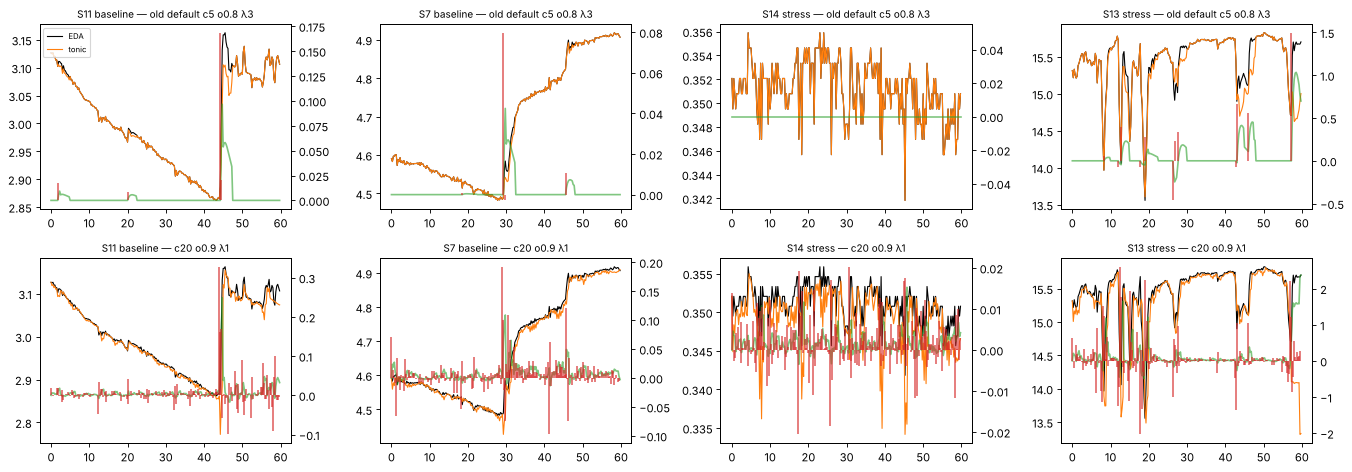

In [11]:
rng = np.random.default_rng(3)
idx = list(rng.choice(np.flatnonzero(y == 1), 2, replace=False)) + list(rng.choice(np.flatnonzero(y == 2), 2, replace=False))
fig, axes = plt.subplots(2, 4, figsize=(17, 6))
t = np.arange(WIN) / FS
for col, i in enumerate(idx):
    for row, (ch, ov, ls, title) in enumerate([(5, 0.8, 3, "old default c5 o0.8 λ3"), (20, 0.9, 1, "c20 o0.9 λ1")]):
        D_, T_, P_ = gmsEDA_window(W[i], ch, ov, ls, 0)
        ax = axes[row, col]
        ax.plot(t, W[i], "k", lw=1, label="EDA"); ax.plot(t, T_, color="tab:orange", lw=1, label="tonic")
        ax2 = ax.twinx(); ax2.plot(t, P_, color="tab:green", alpha=.6, label="phasic")
        ax2.vlines(t, 0, D_, color="tab:red", alpha=.7, label="driver")
        ax.set_title(f"{meta.subject[i]} {'stress' if y[i] == 2 else 'baseline'} — {title}", fontsize=9)
axes[0, 0].legend(fontsize=7, loc="upper left")
plt.tight_layout(); plt.show()

### Which `gms` features drive the gain? (permutation importance, HistGB on `raw+gms`, all subjects)

In [12]:
from sklearn.inspection import permutation_importance
F = SETS[f"raw+gms [{BEST}]"]
m = SCREEN_MODELS["HistGB"]().fit(F.values, y)
imp = permutation_importance(m, F.values, y, n_repeats=5, random_state=0, n_jobs=-1)
pd.Series(imp.importances_mean, index=F.columns).sort_values(ascending=False).head(12).round(4)

p90                  0.0221
gms_drv_events       0.0215
min                  0.0193
gms_drv_bigevents    0.0143
bp_0.5_2.0           0.0141
gms_drv_neg_nnz      0.0130
skew                 0.0110
p10                  0.0056
d_pos_frac           0.0054
n_peaks              0.0047
bp_0.05_0.25         0.0045
range                0.0036
dtype: float64

## 6. Side check: does the tuned decomposition also help *with* per-subject normalisation?
The `raw` features here are robust-normalised per subject: `(x - median) / (p95 - p5)` over the whole recording, with no labels used. With them alone, HistGB reaches 0.938. The tuned `gms` features
are added unchanged: their counts and ratios are scale-free, and the rest are in µS.

In [13]:
RAWN = build_feature_table(W, meta, subject_scale(load_subjects(), "robust")).filter(like="raw_")
resN, pN = compare_feature_sets({"raw (robust-normalised)": RAWN,
                                 f"raw (robust) + gms [{BEST}]": pd.concat([RAWN, GF[BEST]], axis=1)},
                                y, groups, baseline="raw (robust-normalised)")
accN = resN.pivot(index="features", columns="model", values="acc"); accN["mean"] = accN.mean(axis=1)
display(accN.round(3))
pN.round(3)

model,HistGB,LogReg,RandomForest,SVM-RBF,mean
features,,,,,
raw (robust) + gms [c20_o0.9_l1_nn0],0.929,0.894,0.874,0.883,0.895
raw (robust-normalised),0.938,0.876,0.882,0.885,0.895


,features,model,delta,wins,losses,p
0,raw (robust) + gms [c20_o0.9_l1_nn0],LogReg,0.018,7,3,0.508
1,raw (robust) + gms [c20_o0.9_l1_nn0],SVM-RBF,-0.002,7,4,0.722
2,raw (robust) + gms [c20_o0.9_l1_nn0],RandomForest,-0.007,5,3,1.000
3,raw (robust) + gms [c20_o0.9_l1_nn0],HistGB,-0.008,6,5,0.929


## Conclusion

*(The numbers below are for the default `LABELS = (1, 2)`, baseline vs stress. Notebook 05 covers stress vs
non-stress and the 3-class task with amusement.)*

**Without per-subject normalisation, a tuned `gmsEDA` decomposition improves classification.** (Windows from the
project's `reshape_function`, `WINDOWING = "reshape"`; 2,575 windows.)

| features (µS, no normalisation) | LogReg | SVM | RF | HistGB | mean |
|---|---|---|---|---|---|
| raw (33) | 0.833 | 0.855 | 0.829 | 0.843 | 0.840 |
| raw + running-median control | 0.828 | 0.866 | 0.834 | 0.846 | 0.844 |
| raw + gmsEDA, old defaults (5 chops, 0.8, λ 3) | 0.843 | 0.854 | 0.811 | 0.836 | 0.836 |
| **raw + gmsEDA, 20 chops, overlap 0.9, λ 1** | **0.866** | **0.882** | **0.855** | **0.859** | **0.866** |

* **Size and consistency of the gain.** +1.6 to +3.3 accuracy points (mean +2.6); 11 of 15 subjects improve with
  every classifier. The paired Wilcoxon p is 0.006 for SVM and 0.055–0.056 for LogReg and RF (0.20 for HistGB).
  Against the stronger `raw+rel` control the gain is +2.6 to +3.3 (11–12 of 15 subjects, p = 0.002–0.04 for SVM,
  RF and LogReg; 0.08 for HistGB). The naive median decomposition gives almost nothing (+0.004), so the gain comes
  from `gmsEDA`, not from "any tonic/phasic split". The 28 `gmsEDA` features *alone* (0.865) already beat the
  33 raw features.
* **Selection bias accounted for.** With the configuration chosen inside each LOSO fold from all 112 candidates (and
  "no decomposition"), LogReg reaches **0.864** (+3.1 over raw) and HistGB 0.849 (+0.5). Every fold chose a
  `raw+gms` configuration with λ-scale 1 and overlap ≥ 0.8 (20 chops in 9 of 15 folds); none chose raw alone.
* **Parameters.** The old defaults do *not* help. What matters is `lam_scale ≈ 1` together with many chops (10–40, i.e.
  short segments) and high overlap (0.8–0.95): all of the top 11 configurations have λ-scale 1.
  `force_nn=1` is worse (0.850 vs 0.863 in the screen).
* **What the features capture.** Among the most useful `gms` features are the number of (large) driver events and
  the number of negative driver entries. With short segments and λ ≈ 1 the decomposition works as a detector of fast
  rises and falls in the EDA. These counts do not depend on the subject's absolute conductance level, which is
  presumably why they help most when no normalisation is applied. Negative driver values have no direct SCR
  interpretation, so this should be described as an *event/fluctuation representation* rather than a physiological
  SCR decomposition.
* **With per-subject normalisation** (section 6) the same features add nothing (0.895 vs 0.895 mean; HistGB 0.929
  vs 0.938). The normalised raw features already contain that information. Without normalisation, `gmsEDA` raises
  accuracy from ~0.84 to ~0.87 (SVM 0.882).
* **Windowing.** With block-aligned windows (`WINDOWING = "block"`) the same comparison gave 0.837 → 0.875 (+3.8,
  p = 0.002–0.02 for three classifiers). The direction is the same with both windowings; the size of the gain
  (+2.6 vs +3.8 points) depends somewhat on where the windows fall.